### XGBOOST notebook training 
- imports and data loading, deterministic dataset preparation, and train/validation splitting.
- same nine input features.
- 2022 training and 2023 validation periods.
- all fire-positive training observations and the deterministic 2% sample of negatives.
- Python 3.12.5 kernel used to run

#### Cell Overview
1. Library imports	
2. Dataset loading	
3. Deterministic negative sampling	
4. 2022 training / 2023 validation	
5. Nine environmental features	
6. XGBoost training 
7. Model saved	
8. Validation prediction Parquet
9. PR-AUC, ROC-AUC, precision, recall, F1	
10. Threshold selection	
11. Small evaluation files for GitHub

In [12]:
import numpy as np
import pandas as pd
import duckdb
import joblib
import json
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.parquet as pq
import sklearn
import xgboost

from pathlib import Path
from xgboost import XGBClassifier

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Libraries imported successfully!")
print("scikit-learn:", sklearn.__version__)
print("DuckDB:", duckdb.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyArrow:", pa.__version__)
print("Joblib:", joblib.__version__)
print("json:", json.__version__)
print("XGBoost version:", xgboost.__version__)

Libraries imported successfully!
scikit-learn: 1.9.1
DuckDB: 2.0.0
NumPy: 2.5.4
Pandas: 3.0.6
PyArrow: 26.0.0
Joblib: 1.6.0
json: 2.0.9
XGBoost version: 3.4.1


In [13]:
data_path = Path("../data/processed/master_training_dataset.parquet")

if not data_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {data_path}")

print("Dataset found:", data_path)
print("File size (GB):", round(data_path.stat().st_size / 1e9, 2))

# Connect to DuckDB
con = duckdb.connect()

# Inspect dataset columns and data types
schema = con.execute(
    "DESCRIBE SELECT * FROM read_parquet(?)",
    [str(data_path)]
).df()

display(schema)

Dataset found: ../data/processed/master_training_dataset.parquet
File size (GB): 1.13


,column_name,column_type,null,key,default,extra
0,cell_id,INTEGER,YES,None,None,None
1,valid_time,TIMESTAMP_NS,YES,None,None,None
2,number,FLOAT,YES,None,None,None
3,t2m,FLOAT,YES,None,None,None
4,rh2m,FLOAT,YES,None,None,None
5,wind_speed_10m,FLOAT,YES,None,None,None
6,tp,FLOAT,YES,None,None,None
7,ndvi,FLOAT,YES,None,None,None
8,evi,FLOAT,YES,None,None,None
9,longitude,FLOAT,YES,None,None,None


In [14]:
query = """
WITH daily AS (
    SELECT
        cell_id,
        CAST(valid_time AS DATE) AS weather_date,
        t2m,
        rh2m,
        wind_speed_10m,
        tp,
        ndvi,
        evi,
        elevation,
        slope,
        aspect,
        fire_occurred
    FROM read_parquet(?)
    WHERE t2m IS NOT NULL
),

next_day AS (
    SELECT
        a.cell_id,
        a.weather_date,
        b.weather_date AS valid_time,

        a.t2m,
        a.rh2m,
        a.wind_speed_10m,
        a.tp,
        a.ndvi,
        a.evi,
        a.elevation,
        a.slope,
        a.aspect,

        b.fire_occurred
    FROM daily a
    INNER JOIN daily b
        ON a.cell_id = b.cell_id
        AND b.weather_date = a.weather_date + INTERVAL 1 DAY
    WHERE b.weather_date < '2024-01-01'
),

sampled AS (
    SELECT *
    FROM next_day
    WHERE EXTRACT(YEAR FROM valid_time) = 2023
       OR fire_occurred = 1
       OR (
           hash(
               CAST(cell_id AS VARCHAR) || ':' ||
               CAST(valid_time AS VARCHAR)
           ) % 100
       ) < 2
)

SELECT *
FROM sampled
ORDER BY valid_time, cell_id
"""

df = con.execute(
    query,
    [str(data_path)]
).df()

df["valid_time"] = pd.to_datetime(df["valid_time"])
df["weather_date"] = pd.to_datetime(df["weather_date"])

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["fire_occurred"].value_counts())

print("\nDuplicate rows:",
      df.duplicated(["cell_id", "valid_time"]).sum())

display(df.head())

Dataset shape: (28209909, 13)

Class distribution:
fire_occurred
0.0    28202633
1.0        7276
Name: count, dtype: int64

Duplicate rows: 0


,cell_id,weather_date,valid_time,t2m,rh2m,wind_speed_10m,tp,ndvi,evi,elevation,slope,aspect,fire_occurred
0,409,2022-01-01,2022-01-02,261.865540,78.001411,3.082888,0.000035,NaN,NaN,659,89.464157,236.830109,0.0
1,431,2022-01-01,2022-01-02,261.035492,78.330627,3.854872,0.000039,NaN,NaN,576,89.524826,211.778717,0.0
2,451,2022-01-01,2022-01-02,259.924133,79.400047,5.193607,0.000064,NaN,NaN,566,89.130798,54.260223,0.0
3,478,2022-01-01,2022-01-02,259.790375,76.972786,3.345769,0.000065,0.229196,0.109765,232,88.100578,40.292149,0.0
4,522,2022-01-01,2022-01-02,262.139954,77.055847,2.198470,0.000185,0.212067,0.106262,54,35.264389,315.000000,0.0


In [15]:
features = [
    "t2m",
    "rh2m",
    "wind_speed_10m",
    "tp",
    "ndvi",
    "evi",
    "elevation",
    "slope",
    "aspect"
]

# Split by target date
train = df[df["valid_time"].dt.year == 2022].copy()
val = df[df["valid_time"].dt.year == 2023].copy()

X_train = train[features]
y_train = train["fire_occurred"].astype(int)

X_val = val[features]
y_val = val["fire_occurred"].astype(int)

print("Training observations:", len(train))
print("Validation observations:", len(val))

print("\nTraining fire distribution:")
print(y_train.value_counts())

print("\nValidation fire distribution:")
print(y_val.value_counts())

print("\nTraining missing-value rates:")
print(X_train.isna().mean())

assert y_train.nunique() == 2, "Training set needs both classes"
assert y_val.nunique() == 2, "Validation set needs both classes"
assert not df.duplicated(["cell_id", "valid_time"]).any()

Training observations: 554224
Validation observations: 27655685

Training fire distribution:
fire_occurred
0    550616
1      3608
Name: count, dtype: int64

Validation fire distribution:
fire_occurred
0    27652017
1        3668
Name: count, dtype: int64

Training missing-value rates:
t2m               0.000000
rh2m              0.000000
wind_speed_10m    0.000000
tp                0.000000
ndvi              0.035939
evi               0.035939
elevation         0.000000
slope             0.000000
aspect            0.000000
dtype: float64


In [16]:
# Train XGBoost Classifier

xgb = XGBClassifier(
    objective="binary:logistic",
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    min_child_weight=5,
    subsample=1.0,
    colsample_bytree=1.0,
    tree_method="hist",
    eval_metric="logloss",
    random_state=42,
    n_jobs=4
)

# Adjust for the 2% negative training sample
sample_weights = np.where(
    y_train.to_numpy() == 1,
    1.0,
    50.0
)

xgb.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

print("XGBoost training complete!")

XGBoost training complete!


,Feature,Importance
5,evi,0.709918
6,elevation,0.214212
4,ndvi,0.050109
3,tp,0.009643
1,rh2m,0.005954
0,t2m,0.004488
7,slope,0.003023
2,wind_speed_10m,0.001385
8,aspect,0.001268


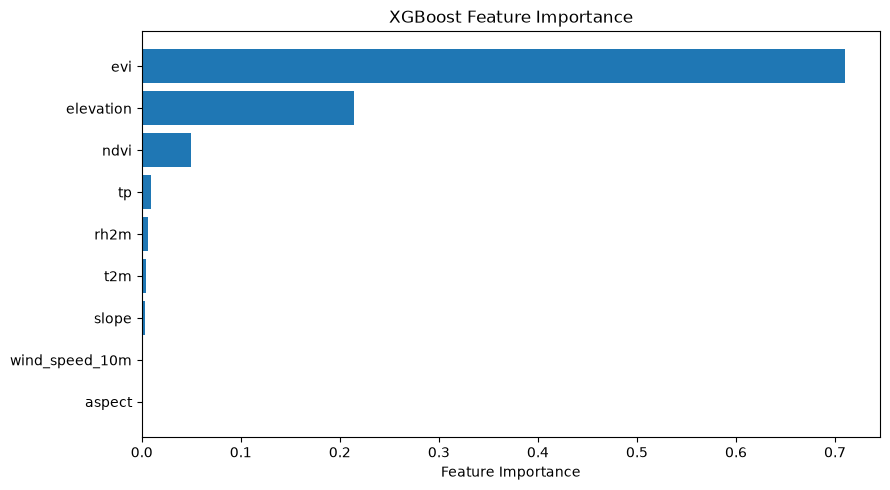

In [17]:
# XGBoost Feature Importance

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": xgb.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(9, 5))
plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.title("XGBoost Feature Importance")
plt.tight_layout()
plt.show()

In [18]:
# Save XGBoost Model and Validation Predictions

project_root = data_path.parents[2]

models_dir = project_root / "models"
outputs_dir = project_root / "outputs"

models_dir.mkdir(exist_ok=True)
outputs_dir.mkdir(exist_ok=True)

model_path = models_dir / "xgboost_provisional.joblib"

joblib.dump({
    "model": xgb,
    "features": features
}, model_path)

output_path = outputs_dir / "xgb_validation_predictions.parquet"

batch_size = 250_000
xgb_threshold = 0.5

writer = None

try:
    for start in range(0, len(X_val), batch_size):
        end = min(start + batch_size, len(X_val))

        probabilities = xgb.predict_proba(
            X_val.iloc[start:end]
        )[:, 1]

        batch = val.iloc[start:end][
            ["cell_id", "weather_date", "valid_time"]
        ].copy()

        batch["y_true"] = y_val.iloc[start:end].to_numpy()
        batch["y_prob"] = probabilities
        batch["y_pred"] = (
            probabilities >= xgb_threshold
        ).astype(int)

        batch["model"] = "XGBoost"
        batch["threshold"] = xgb_threshold

        table = pa.Table.from_pandas(
            batch,
            preserve_index=False
        )

        if writer is None:
            writer = pq.ParquetWriter(
                str(output_path),
                table.schema,
                compression="zstd"
            )

        writer.write_table(table)

        print(f"Processed {end:,} / {len(X_val):,} rows")

finally:
    if writer is not None:
        writer.close()

print("Saved model:", model_path)
print("Saved predictions:", output_path)

Processed 250,000 / 27,655,685 rows
Processed 500,000 / 27,655,685 rows
Processed 750,000 / 27,655,685 rows
Processed 1,000,000 / 27,655,685 rows
Processed 1,250,000 / 27,655,685 rows
Processed 1,500,000 / 27,655,685 rows
Processed 1,750,000 / 27,655,685 rows
Processed 2,000,000 / 27,655,685 rows
Processed 2,250,000 / 27,655,685 rows
Processed 2,500,000 / 27,655,685 rows
Processed 2,750,000 / 27,655,685 rows
Processed 3,000,000 / 27,655,685 rows
Processed 3,250,000 / 27,655,685 rows
Processed 3,500,000 / 27,655,685 rows
Processed 3,750,000 / 27,655,685 rows
Processed 4,000,000 / 27,655,685 rows
Processed 4,250,000 / 27,655,685 rows
Processed 4,500,000 / 27,655,685 rows
Processed 4,750,000 / 27,655,685 rows
Processed 5,000,000 / 27,655,685 rows
Processed 5,250,000 / 27,655,685 rows
Processed 5,500,000 / 27,655,685 rows
Processed 5,750,000 / 27,655,685 rows
Processed 6,000,000 / 27,655,685 rows
Processed 6,250,000 / 27,655,685 rows
Processed 6,500,000 / 27,655,685 rows
Processed 6,750,00

In [19]:
# XGBoost - Validation Metrics

xgb_results = pd.read_parquet(
    output_path,
    columns=["y_true", "y_prob", "y_pred"]
)

y_true_xgb = xgb_results["y_true"].to_numpy()
y_prob_xgb = xgb_results["y_prob"].to_numpy()
y_pred_xgb = xgb_results["y_pred"].to_numpy()

xgb_metrics = {
    "model": "XGBoost",
    "dataset": "2023 Validation",
    "threshold": xgb_threshold,
    "pr_auc": float(average_precision_score(y_true_xgb, y_prob_xgb)),
    "roc_auc": float(roc_auc_score(y_true_xgb, y_prob_xgb)),
    "precision": float(precision_score(y_true_xgb, y_pred_xgb, zero_division=0)),
    "recall": float(recall_score(y_true_xgb, y_pred_xgb, zero_division=0)),
    "f1": float(f1_score(y_true_xgb, y_pred_xgb, zero_division=0)),
    "baseline_pr_auc": float(y_true_xgb.mean())
}

print("XGBoost Validation Results")
print("--------------------------")

for metric, value in xgb_metrics.items():
    print(f"{metric}: {value}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true_xgb, y_pred_xgb))

# Save metrics and feature importance
metrics_path = outputs_dir / "xgb_validation_metrics.json"

with open(metrics_path, "w") as f:
    json.dump(xgb_metrics, f, indent=4)

feature_importance.to_csv(
    outputs_dir / "xgb_feature_importance.csv",
    index=False
)

print("\nMetrics and feature importance saved.")

XGBoost Validation Results
--------------------------
model: XGBoost
dataset: 2023 Validation
threshold: 0.5
pr_auc: 0.2672804794324749
roc_auc: 0.9482032709622054
precision: 0.28758730547726996
recall: 0.6398582333696837
f1: 0.39682137120635724
baseline_pr_auc: 0.00013263095815561971

Confusion Matrix:
[[27646203     5814]
 [    1321     2347]]

Metrics and feature importance saved.


In [20]:
# XGBoost - Threshold Analysis

positive_scores = np.sort(y_prob_xgb[y_true_xgb == 1])
negative_scores = np.sort(y_prob_xgb[y_true_xgb == 0])

thresholds = np.unique(np.concatenate([
    np.linspace(0.01, 0.99, 50),
    np.quantile(positive_scores, np.linspace(0, 1, 101)),
    [0.5]
]))

total_positives = len(positive_scores)
results = []

for threshold in thresholds:
    tp = total_positives - np.searchsorted(
        positive_scores, threshold, side="left"
    )
    fp = len(negative_scores) - np.searchsorted(
        negative_scores, threshold, side="left"
    )
    fn = total_positives - tp

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / total_positives
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    results.append({
        "threshold": float(threshold),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "predicted_fires": int(tp + fp),
        "true_positives": int(tp),
        "false_positives": int(fp),
        "false_negatives": int(fn)
    })

threshold_df = pd.DataFrame(results)

best_row = threshold_df.loc[threshold_df["f1"].idxmax()]
best_threshold = float(best_row["threshold"])

print("Best tested F1 threshold:", best_threshold)
print("\nMetrics at selected threshold:")
display(best_row.to_frame().T)

print("\nTop 10 tested thresholds by F1:")
display(threshold_df.nlargest(10, "f1"))

threshold_df.to_csv(
    outputs_dir / "xgb_threshold_analysis.csv",
    index=False
)

print("Threshold analysis saved successfully!")

Best tested F1 threshold: 0.6900000000000001

Metrics at selected threshold:


,threshold,precision,recall,f1,predicted_fires,true_positives,false_positives,false_negatives
77,0.69,0.30876,0.564068,0.399074,6701.0,2069.0,4632.0,1599.0



Top 10 tested thresholds by F1:


,threshold,precision,recall,f1,predicted_fires,true_positives,false_positives,false_negatives
77,0.690000,0.308760,0.564068,0.399074,6701,2069,4632,1599
71,0.624695,0.301225,0.589967,0.398820,7184,2164,5020,1504
72,0.630000,0.301792,0.587786,0.398816,7144,2156,4988,1512
76,0.670000,0.306338,0.569248,0.398321,6816,2088,4728,1580
65,0.550000,0.293419,0.619956,0.398318,7750,2274,5476,1394
64,0.549839,0.293268,0.619956,0.398179,7754,2274,5480,1394
70,0.610000,0.299041,0.595147,0.398067,7300,2183,5117,1485
73,0.644587,0.302991,0.579880,0.398016,7020,2127,4893,1541
78,0.696536,0.308501,0.559978,0.397831,6658,2054,4604,1614
74,0.650000,0.303605,0.576336,0.397705,6963,2114,4849,1554


Threshold analysis saved successfully!


In [21]:
# XGBoost - Final Output Verification

required_files = [
    model_path,
    output_path,
    metrics_path,
    outputs_dir / "xgb_feature_importance.csv",
    outputs_dir / "xgb_threshold_analysis.csv"
]

for path in required_files:
    assert path.exists(), f"Missing output: {path}"
    print("Verified:", path.name)

assert len(xgb_results) == len(y_val)
assert xgb_results["y_true"].isin([0, 1]).all()
assert xgb_results["y_prob"].between(0, 1).all()

print("\nAll XGBoost outputs verified successfully!")

Verified: xgboost_provisional.joblib
Verified: xgb_validation_predictions.parquet
Verified: xgb_validation_metrics.json
Verified: xgb_feature_importance.csv
Verified: xgb_threshold_analysis.csv

All XGBoost outputs verified successfully!
